# Image Captioning with CLIP Prefixes (ClipCap): How an Image Becomes a Sentence

**CHEM 584: Introduction to Machine Learning and Quantum Computing**

Prof. Victor S. Batista

*Adapted from the inference notebook of the authors of ClipCap (R. Mokady, A. Hertz, A. H. Bermano), https://github.com/rmokady/CLIP_prefix_caption. The authors of this tutorial do not own any rights to the original code, models or data; please see the original repository for the license terms.*

**Version 2.0 · November 2026 · runs on Google Colab (a GPU runtime is recommended; CPU works, only slower).**
**How to cite:** V. S. Batista, *Image captioning with CLIP prefixes (ClipCap)*, CHEM 584 tutorial notebook, version 2.0 (2026).

## 1. Introduction

**Image captioning** is the task of describing an image with a sentence. It looks simple for a person and is a good test of whether a machine *understands* an image: the system must recognise objects, their attributes and their relations, and then put them into fluent language. Until recently, captioning models were trained from scratch on hundreds of thousands of image-caption pairs. **ClipCap** takes a different route: it combines two very large **pre-trained** models that were never trained together, and learns only a small **bridge** between them:

* **CLIP**, which turns an image into a vector (an *embedding*) that captures its meaning;
* **GPT-2**, a language model that continues any text it is given.

The bridge turns the CLIP embedding into a short sequence of vectors, the **prefix**, that GPT-2 reads *as if it were the beginning of a sentence*. GPT-2 then simply continues the text, and the continuation is the caption.

### What you will learn
After working through this notebook you will be able to:
1. explain what a **CLIP embedding** is and how a **prefix** conditions a language model on an image;
2. follow the shapes of all tensors in the model, from the image to the first token of the caption;
3. explain and compare three **decoding strategies**: greedy decoding, **top-p (nucleus) sampling** and **beam search**, and implement them;
4. generate captions for your own images with two pre-trained models (trained on COCO and on Conceptual Captions) and compare their styles;
5. **evaluate** captions without reference sentences, using a CLIP similarity score, and probe the model with simple experiments (does the image really matter? what does the prefix look like?);
6. recognise the **limitations and biases** of captioning models.

### What you need
Basic Python and PyTorch, and a rough idea of what a neural network and a Transformer are. Everything needed about CLIP, GPT-2 and decoding is explained in Section 2.

### Roadmap

| Section | Content |
|---|---|
| 2 | Background: CLIP, prefixes, GPT-2, decoding |
| 3 | Setup: install, settings, imports |
| 4 | The model: CLIP + mapping network + GPT-2, and loading the pre-trained weights |
| 5 | From an image to a prefix |
| 6 | Decoding: greedy, top-p sampling, beam search |
| 7 | Captioning a gallery of images, with a CLIP similarity score |
| 8 | Looking inside: does the image matter? what does the prefix look like? |
| 9 | Exploring sampling; comparing the COCO and Conceptual Captions models |
| 10 | Your own images, limitations and ethics; exercises, questions, references |

> **What changed since 2022.** The original notebook used PyDrive (which needs authentication and is no longer available in Colab), installed OpenAI's CLIP from GitHub, imported `AdamW` from `transformers` (removed from current versions), and its function `generate2`, described as top-p sampling, in fact performs **greedy** decoding (see Section 6). This version downloads the weights with `gdown`, uses the Hugging Face copy of CLIP, loads the old checkpoints robustly, and implements all three decoders explicitly.

**How to run.** Run the cells from top to bottom. Cells whose code is hidden (form cells) are plumbing or figures; click *Show code* to see them.

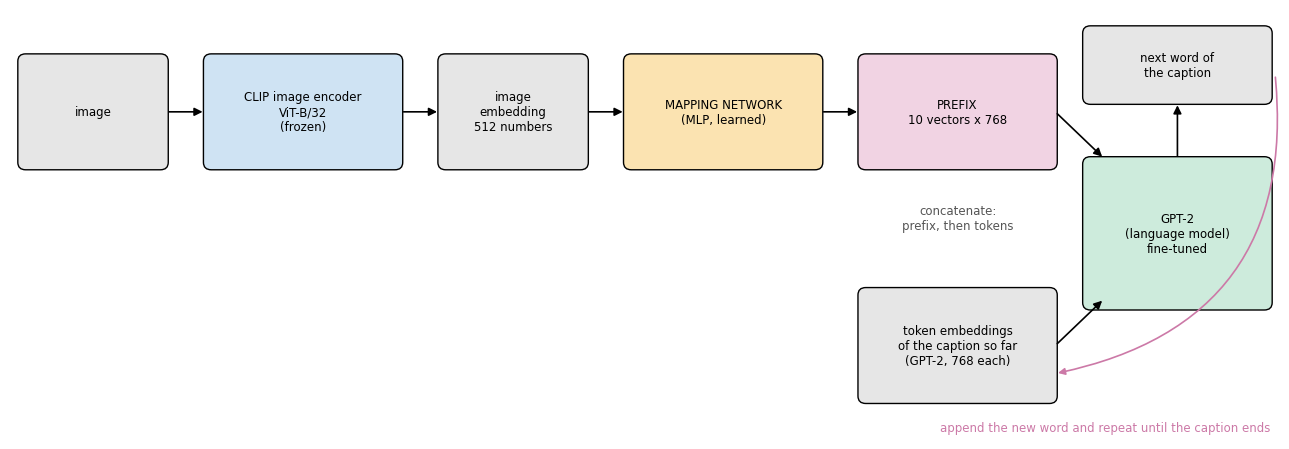

In [1]:
#@title Figure 1: the ClipCap model at a glance { display-mode: "form" }
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def box(ax, x, y, w, h, text, fc, fs=8.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=fc, ec="k", lw=1))
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=fs)

def arrow(ax, p, q, color="k", rad=0.0):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=12, lw=1.2, color=color, connectionstyle=f"arc3,rad={rad}"))

fig, ax = plt.subplots(figsize=(13, 4.6))
ax.set_xlim(0, 13); ax.set_ylim(0, 4.6); ax.axis("off")
blue, orange, green, gray, pink = "#cfe3f3", "#fbe3b1", "#cdebdc", "#e6e6e6", "#f1d3e3"
box(ax, 0.1, 2.9, 1.5, 1.2, "image", gray)
box(ax, 2.0, 2.9, 2.0, 1.2, "CLIP image encoder\nViT-B/32\n(frozen)", blue)
box(ax, 4.4, 2.9, 1.5, 1.2, "image\nembedding\n512 numbers", gray)
box(ax, 6.3, 2.9, 2.0, 1.2, "MAPPING NETWORK\n(MLP, learned)", orange)
box(ax, 8.7, 2.9, 2.0, 1.2, "PREFIX\n10 vectors x 768", pink)
for x0, x1 in [(1.6, 2.0), (4.0, 4.4), (5.9, 6.3), (8.3, 8.7)]:
    arrow(ax, (x0, 3.5), (x1, 3.5))
box(ax, 8.7, 0.4, 2.0, 1.2, "token embeddings\nof the caption so far\n(GPT-2, 768 each)", gray)
box(ax, 11.0, 1.4, 1.9, 1.6, "GPT-2\n(language model)\nfine-tuned", green)
arrow(ax, (10.7, 3.5), (11.2, 3.0)); arrow(ax, (10.7, 1.0), (11.2, 1.5))
ax.text(9.7, 2.25, "concatenate:\nprefix, then tokens", ha="center", fontsize=8.5, color="#555")
box(ax, 11.0, 3.6, 1.9, 0.8, "next word of\nthe caption", gray)
arrow(ax, (11.95, 3.0), (11.95, 3.6))
ax.annotate("", xy=(10.7, 0.7), xytext=(12.95, 3.9), arrowprops=dict(arrowstyle="-|>", color="#CC79A7", lw=1.2, connectionstyle="arc3,rad=-0.45"))
ax.text(12.9, 0.12, "append the new word and repeat until the caption ends", ha="right", va="center", fontsize=8.5, color="#CC79A7")
plt.tight_layout(); plt.show()

**Figure 1.** ClipCap. The frozen **CLIP** encoder turns the image into one vector of 512 numbers. A small learned **mapping network** expands it into a **prefix** of 10 vectors of size 768, the size of GPT-2's word embeddings. The prefix is placed in front of the embeddings of the caption written so far, and **GPT-2** predicts the next word. The new word is appended and the process repeats until the caption ends. The image enters only through the prefix.

## 2. Background

### 2.1 CLIP: a shared space for images and text
CLIP (*Contrastive Language-Image Pre-training*, Radford et al., 2021) consists of an **image encoder** and a **text encoder** that were trained together on about 400 million image-text pairs from the internet. The training objective is *contrastive*: the embedding of an image should be **close** (in cosine similarity) to the embedding of its own caption, and **far** from the embeddings of the captions of other images. As a result, an image and a sentence that describe the same thing end up with similar vectors. The image embedding therefore contains a rich, language-aligned summary of the picture. We use the **ViT-B/32** version, whose image encoder is a Vision Transformer that splits the image into 32 × 32 pixel patches and outputs a vector of **512** numbers.

### 2.2 GPT-2: a language model
A language model assigns a probability to the next word (more exactly, the next *token*, a word or a part of a word) given the words so far:
$$p(w_t\,|\,w_1,\dots,w_{t-1}).$$
GPT-2 is a Transformer that was trained on a very large amount of text to do exactly this. It first converts each token into a vector of 768 numbers (its **embedding**), then processes the whole sequence, and finally outputs a probability for every one of the 50,257 tokens of its vocabulary. Importantly, GPT-2 can be given *embeddings directly*, not only tokens.

### 2.3 The idea of ClipCap: the prefix
How can a language model "see"? ClipCap uses the following trick. The caption is generated by GPT-2 as usual, but the sequence it reads *starts with the prefix*, a short sequence of vectors derived from the image:
$$\big[\,p_1,\dots,p_{10},\;e(w_1),\dots,e(w_{t-1})\,\big]\;\longrightarrow\;p(w_t\,|\,\text{image},\,w_1,\dots,w_{t-1}),$$
where $e(w)$ is the embedding of the token $w$. The prefix vectors $p_1,\dots,p_{10}$ are produced by a **mapping network** from the CLIP embedding $c$ (512 numbers): here a multilayer perceptron (MLP) with one hidden layer of 3840 units and a $\tanh$ activation, whose output of $10\times768=7680$ numbers is reshaped into 10 vectors. The idea is related to *prefix tuning* of language models. During training, only the mapping network (and, in the models that we use, also GPT-2) is learned; CLIP stays frozen. Since CLIP embeddings already carry the meaning of the image, only a simple translation to GPT-2's "language" has to be learned, which makes training cheap compared with building a captioner from scratch.

### 2.4 Decoding: from probabilities to a sentence
At each step the model gives a probability distribution over the next token. How do we choose the token?

* **Greedy decoding.** Always take the most probable token. It is fast and deterministic, but it can miss sentences whose first words are not the most probable ones.
* **Top-$p$ (nucleus) sampling.** Sort the tokens by probability, keep the smallest set whose probabilities add up to at least $p$ (for example 0.8), renormalise, and **sample** from it. A *temperature* $T$ divides the logits before the softmax: $T<1$ sharpens the distribution (safer), $T>1$ flattens it (more varied). The result is random: different runs give different captions.
* **Beam search.** Keep the best $B$ partial sentences (the *beams*) at every step, extend each by every possible token, and keep the $B$ best of the extensions, ranked by their total log-probability (here normalised by the length, so that short sentences are not favoured). At the end the best-scoring complete sentence is returned. It is deterministic and explores many more sentences than greedy decoding, at $B$ times the cost.

A caption ends when the model produces the **stop token**, here a full stop `.`.

## 3. Setup

### 3.1 Install the packages
Colab provides PyTorch and `transformers`. We only add `gdown`, to download the pre-trained ClipCap weights from Google Drive without having to log in. We use the **Hugging Face copy of OpenAI's CLIP** instead of installing OpenAI's package from GitHub, which keeps the installation simple.

In [2]:
#@title Install the packages { display-mode: "form" }
%pip install -q -U gdown

### 3.2 Settings
| Setting | Meaning |
|---|---|
| `MODEL` | which pre-trained ClipCap model to use for the captions: trained on the **Conceptual Captions** data set or on **COCO** (Section 9 compares them) |
| `BEAM_SIZE` | number of beams of the beam search |
| `SEED` | random seed for the sampling experiments |
| `COMPARE_MODELS` | also download the other model, to compare the two in Section 9.2 |

In [3]:
#@title Settings { display-mode: "form" }
MODEL = "Conceptual captions" #@param ["Conceptual captions", "COCO"]
BEAM_SIZE = 5 #@param {type:"integer"}
SEED = 0 #@param {type:"integer"}
COMPARE_MODELS = False #@param {type:"boolean"}

### 3.3 Imports, device and versions

In [4]:
import os, sys, io, textwrap, time, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import PIL.Image
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoTokenizer, GPT2LMHeadModel, CLIPModel, CLIPProcessor
import transformers, gdown

IN_COLAB = "google.colab" in sys.modules
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED); np.random.seed(SEED)
WORKDIR = "/content" if IN_COLAB else "."

COLORS = dict(blue="#0072B2", orange="#E69F00", green="#009E73", red="#D55E00", pink="#CC79A7", gray="#7f7f7f")   # colour-blind safe
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

print(f"python {sys.version.split()[0]} | torch {torch.__version__} | transformers {transformers.__version__} | numpy {np.__version__}")
print("device:", device, f"({torch.cuda.get_device_name(0)})" if device.type == "cuda" else "(no GPU: captions will take a few seconds each)")

python 3.13.16 | torch 2.14.1+cu130 | transformers 5.22.1 | numpy 2.4.6
device: cuda (Tesla T4)


## 4. The model

### 4.1 The mapping network and the captioning model
The model is a small PyTorch class that holds GPT-2 and the mapping network `clip_project`.

* `MLP` is the mapping network: linear layer (512 → 3840), $\tanh$, linear layer (3840 → 7680).
* `forward` shows exactly how the image enters the language model: the prefix (the mapping of the CLIP embedding, reshaped to 10 × 768) is **concatenated** in front of the token embeddings, and GPT-2 reads the result through its `inputs_embeds` argument. (This is the function used in *training*; at inference we call the parts of it directly, in Section 6.)

The names of the layers (`gpt`, `clip_project.model.0`, ...) must match those of the saved weights.

In [5]:
PREFIX_LENGTH = 10      # number of prefix vectors
CLIP_SIZE = 512         # size of the CLIP embedding

class MLP(nn.Module):
    """The mapping network: Linear -> Tanh -> Linear."""
    def __init__(self, sizes, bias=True, act=nn.Tanh):
        super().__init__()
        layers = []
        for i in range(len(sizes) - 1):
            layers.append(nn.Linear(sizes[i], sizes[i + 1], bias=bias))
            if i < len(sizes) - 2:
                layers.append(act())
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)


class ClipCaptionModel(nn.Module):
    """GPT-2 plus a mapping network that turns a CLIP embedding into a prefix of GPT-2 embeddings."""
    def __init__(self, prefix_length=PREFIX_LENGTH, prefix_size=CLIP_SIZE):
        super().__init__()
        self.prefix_length = prefix_length
        self.gpt = GPT2LMHeadModel.from_pretrained("gpt2")
        self.gpt_embedding_size = self.gpt.transformer.wte.weight.shape[1]          # 768
        self.clip_project = MLP((prefix_size, (self.gpt_embedding_size * prefix_length) // 2,
                                 self.gpt_embedding_size * prefix_length))          # 512 -> 3840 -> 7680

    def prefix_from_clip(self, clip_embedding):
        """(batch, 512) -> (batch, 10, 768)"""
        return self.clip_project(clip_embedding).view(-1, self.prefix_length, self.gpt_embedding_size)

    def forward(self, tokens, clip_embedding):
        """Next-token logits for a caption (as token ids) given the CLIP embedding of its image."""
        prefix = self.prefix_from_clip(clip_embedding)                              # (batch, 10, 768)
        text = self.gpt.transformer.wte(tokens)                                     # (batch, length, 768)
        embeddings = torch.cat((prefix, text), dim=1)                               # prefix first, then the words
        return self.gpt(inputs_embeds=embeddings).logits

### 4.2 CLIP and the tokenizer
We load CLIP ViT-B/32 (the Hugging Face copy of OpenAI's weights) and the GPT-2 tokenizer. The `CLIPProcessor` resizes and normalises images exactly as CLIP expects. We use only the **image** side of CLIP to build the prefix, and, in Section 7, also its **text** side to score the captions.

In [6]:
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").float().to(device).eval()
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
tokenizer = AutoTokenizer.from_pretrained("gpt2")

n_clip_image = sum(p.numel() for p in clip_model.vision_model.parameters()) + clip_model.visual_projection.weight.numel()
print(f"CLIP image encoder: {n_clip_image / 1e6:.0f} million parameters (frozen)")
print("GPT-2 vocabulary size:", tokenizer.vocab_size, "| stop token '.' has id", tokenizer.encode(".")[0])

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (8 outputs left out)

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

CLIP image encoder: 88 million parameters (frozen)
GPT-2 vocabulary size: 50257 | stop token '.' has id 13


### 4.3 The pre-trained weights
The authors of ClipCap trained models on two data sets, which we can load: **COCO** (about 120,000 images, each with 5 captions written by people who describe what they see) and **Conceptual Captions** (about 3 million web images with their *alt-text*, automatically cleaned, for instance by replacing names with generic words such as "actor"). The weights are public files on Google Drive (each about 0.6 GB: GPT-2, 124 million parameters, plus the mapping network). The next cell downloads them with `gdown`. If the download fails (Google Drive sometimes limits popular files), the cell tells you how to download the file by hand and upload it.

The old checkpoints were saved with an older `transformers` version and contain some entries that current versions no longer use (the fixed attention masks `attn.bias` and `attn.masked_bias` of GPT-2). The loading function removes them and **checks that every parameter of the model has been found** in the file, so that a silently wrong model is impossible.

In [7]:
WEIGHTS = {"Conceptual captions": ("14pXWwB4Zm82rsDdvbGguLfx9F8aM7ovT", "conceptual_captions"),
           "COCO":                ("1IdaBtMSvtyzF0ByVaBHtvM0JYSXRExRX", "coco")}
WEIGHTS_DIR = os.path.join(WORKDIR, "pretrained_models")
os.makedirs(WEIGHTS_DIR, exist_ok=True)

def download_weights(which):
    file_id, key = WEIGHTS[which]
    path = os.path.join(WEIGHTS_DIR, f"{key}_weights.pt")
    if not (os.path.isfile(path) and os.path.getsize(path) > 100e6):
        print(f"Downloading the {which} weights (about 0.6 GB) ...")
        gdown.download(id=file_id, output=path, quiet=False)
    if not (os.path.isfile(path) and os.path.getsize(path) > 100e6):
        print(f"The automatic download failed. Download the file by hand from https://drive.google.com/uc?id={file_id}")
        if IN_COLAB:
            from google.colab import files
            print("then select it in the dialog below.")
            up = files.upload()
            if up:
                os.replace(next(iter(up)), path)
        if not os.path.isfile(path):
            raise FileNotFoundError(f"weights file not found: {path}")
    return path

def load_captioner(which):
    path = download_weights(which)
    m = ClipCaptionModel(PREFIX_LENGTH)
    state = torch.load(path, map_location="cpu", weights_only=True)
    state = {k: v for k, v in state.items() if not k.endswith((".attn.bias", ".attn.masked_bias"))}   # entries of old versions
    missing, unexpected = m.load_state_dict(state, strict=False)
    missing = [k for k in missing if k != "gpt.lm_head.weight"]                                       # tied to the token embedding
    if missing or unexpected:
        raise RuntimeError(f"The weights do not match the model.\nmissing: {missing[:5]}\nunexpected: {unexpected[:5]}")
    return m.float().to(device).eval()

captioners = {MODEL: load_captioner(MODEL)}
model = captioners[MODEL]
n_gpt = sum(p.numel() for p in model.gpt.parameters())
n_map = sum(p.numel() for p in model.clip_project.parameters())
print(f"loaded '{MODEL}': GPT-2 {n_gpt / 1e6:.0f} M parameters + mapping network {n_map / 1e6:.1f} M parameters")

Downloading...
From (original): https://drive.google.com/uc?id=14pXWwB4Zm82rsDdvbGguLfx9F8aM7ovT
From (redirected): https://drive.google.com/uc?id=14pXWwB4Zm82rsDdvbGguLfx9F8aM7ovT&confirm=t&uuid=a441cfdb-425e-4ddf-8fb0-e363bdf64187
To: /content/pretrained_models/conceptual_captions_weights.pt
100%|██████████| 636M/636M [00:14<00:00, 43.2MB/s]


model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

loaded 'Conceptual captions': GPT-2 124 M parameters + mapping network 31.5 M parameters


## 5. From an image to a prefix

### 5.1 Some images
We use eight test images from the COCO data set (the "Karpathy test split" that the authors used) and download them from the COCO server. You can also upload your own images in Section 10.

In [8]:
COCO_IDS = ["562207", "579664", "060623", "165547", "334321", "483108", "386164", "354533"]
IMAGES_DIR = os.path.join(WORKDIR, "images")
os.makedirs(IMAGES_DIR, exist_ok=True)

def fetch_coco(image_id):
    name = f"COCO_val2014_000000{image_id}.jpg"
    path = os.path.join(IMAGES_DIR, name)
    if not os.path.isfile(path):
        try:
            urllib.request.urlretrieve(f"https://images.cocodataset.org/val2014/{name}", path)
        except Exception:
            urllib.request.urlretrieve(f"http://images.cocodataset.org/val2014/{name}", path)
    return PIL.Image.open(path).convert("RGB")

images = {}
for i in COCO_IDS:
    try:
        images[f"COCO {i}"] = fetch_coco(i)
    except Exception as err:
        print(f"could not download COCO image {i}: {err}")
print(f"{len(images)} images available")

8 images available


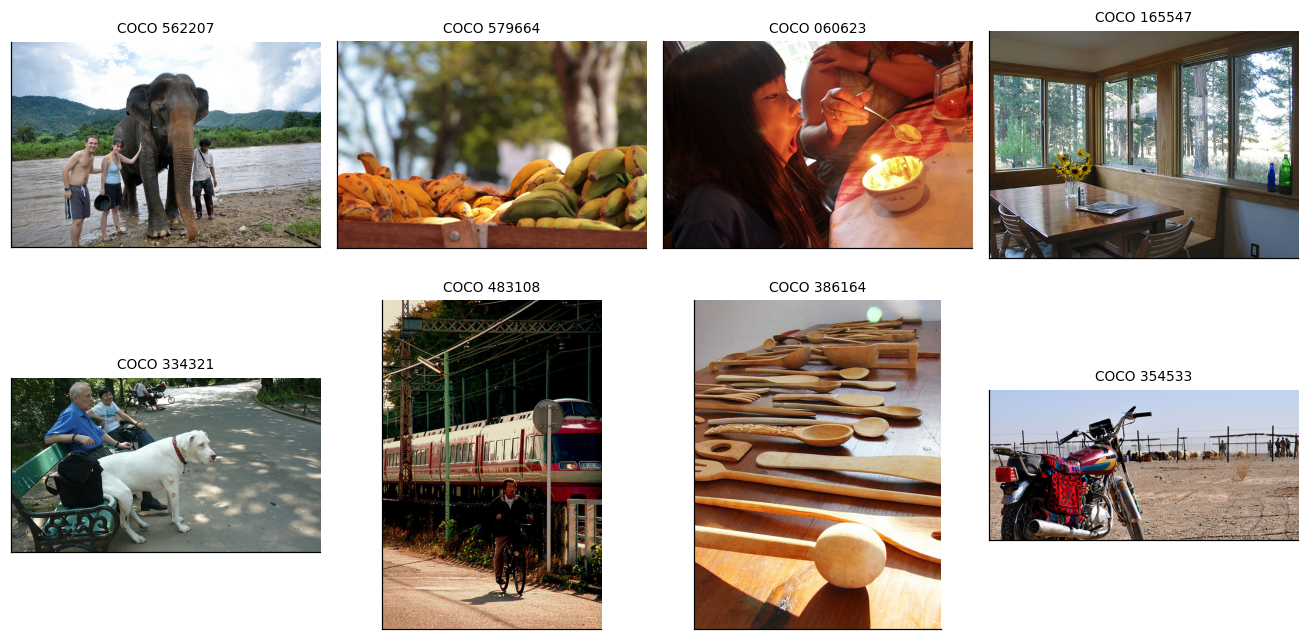

In [9]:
#@title Figure 2: the images { display-mode: "form" }
fig, axes = plt.subplots(2, 4, figsize=(12, 6.2))
for a, (name, im) in zip(axes.ravel(), images.items()):
    a.imshow(im); a.set_xticks([]); a.set_yticks([]); a.set_title(name, fontsize=9)
for a in axes.ravel()[len(images):]:
    a.axis("off")
plt.tight_layout(); plt.show()

**Figure 2.** The eight test images.

### 5.2 CLIP embedding and prefix
We now compute the CLIP embedding of an image and turn it into a prefix. Note two details: the ClipCap models were trained with the **raw** CLIP embedding (we do *not* normalise it to length 1), and the mapping network's output is reshaped into 10 vectors of 768 numbers.

In [10]:
@torch.no_grad()
def clip_image_embedding(pil_image):
    """(1, 512) CLIP embedding of an image, not normalised (this is what ClipCap was trained with)."""
    pixel_values = clip_processor(images=pil_image.convert("RGB"), return_tensors="pt")["pixel_values"].to(device)
    pooled = clip_model.vision_model(pixel_values=pixel_values).pooler_output        # (1, 768): the [CLS] token after the final layer norm
    return clip_model.visual_projection(pooled).float()                              # (1, 512): projection into the shared image-text space

@torch.no_grad()
def make_prefix(pil_image, captioner=None):
    captioner = captioner or model
    return captioner.prefix_from_clip(clip_image_embedding(pil_image))               # (1, 10, 768)

name0 = next(iter(images))
c0 = clip_image_embedding(images[name0])
p0 = make_prefix(images[name0])
print(f"image '{name0}' -> CLIP embedding {tuple(c0.shape)} (length {c0.norm().item():.1f}) -> prefix {tuple(p0.shape)}")

image 'COCO 562207' -> CLIP embedding (1, 512) (length 10.1) -> prefix (1, 10, 768)


## 6. Decoding

We now have a prefix; the model can generate the caption one token at a time. In every decoder the loop is the same: feed the sequence of embeddings (prefix followed by the tokens so far) to GPT-2, take the logits of the **last** position (they give the distribution of the next token), choose a token, append its embedding, and stop at the full stop or after `entry_length` tokens. The decoders differ only in *how the token is chosen*.

> **A bug in the original code.** The function `generate2` of the original notebook is meant to be top-$p$ sampling. It removes the tokens outside the nucleus, but then chooses the next token with `torch.argmax`, which always returns the single most probable token. The nucleus always contains that token, and a temperature does not change which token is largest, so `top_p` and `temperature` had **no effect**: `generate2` is greedy decoding. Below we implement greedy decoding and top-$p$ sampling as separate functions.

In [11]:
@torch.no_grad()
def _embed(model, token):                                  # (1, 1) token ids -> (1, 1, 768) embeddings
    return model.gpt.transformer.wte(token)

@torch.no_grad()
def generate_greedy(model, prefix_embed, entry_length=67, stop_token="."):
    """Greedy decoding: always the most probable token."""
    model.eval()
    stop_index = tokenizer.encode(stop_token)[0]
    generated, tokens = prefix_embed, []
    for _ in range(entry_length):
        logits = model.gpt(inputs_embeds=generated).logits[:, -1, :]                 # distribution of the next token
        next_token = logits.argmax(-1, keepdim=True)                                 # (1, 1)
        tokens.append(next_token.item())
        generated = torch.cat((generated, _embed(model, next_token)), dim=1)
        if next_token.item() == stop_index:
            break
    return tokenizer.decode(tokens).strip()

def top_p_filter(logits, top_p):
    """Set the logits outside the nucleus (the smallest set of tokens with total probability >= top_p) to -inf."""
    sorted_logits, sorted_index = torch.sort(logits, descending=True, dim=-1)
    cumulative = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
    remove = cumulative > top_p
    remove[..., 1:] = remove[..., :-1].clone()                                       # keep the token that crosses the threshold
    remove[..., 0] = False                                                           # always keep the most probable token
    to_remove = torch.zeros_like(logits, dtype=torch.bool).scatter(-1, sorted_index, remove)
    return logits.masked_fill(to_remove, -float("inf"))

@torch.no_grad()
def generate_top_p(model, prefix_embed, top_p=0.8, temperature=1.0, entry_length=67, stop_token=".", seed=None):
    """Top-p (nucleus) sampling with a temperature: the next token is DRAWN from the nucleus."""
    model.eval()
    stop_index = tokenizer.encode(stop_token)[0]
    gen = None if seed is None else torch.Generator(device=prefix_embed.device).manual_seed(seed)
    generated, tokens = prefix_embed, []
    for _ in range(entry_length):
        logits = model.gpt(inputs_embeds=generated).logits[:, -1, :] / max(temperature, 1e-6)
        probs = F.softmax(top_p_filter(logits, top_p), dim=-1)
        next_token = torch.multinomial(probs, 1, generator=gen)                      # (1, 1): a random draw
        tokens.append(next_token.item())
        generated = torch.cat((generated, _embed(model, next_token)), dim=1)
        if next_token.item() == stop_index:
            break
    return tokenizer.decode(tokens).strip()

@torch.no_grad()
def generate_beam(model, prefix_embed, beam_size=5, entry_length=67, stop_token=".", return_scores=False):
    """Beam search: keep the `beam_size` best partial sentences; scores are mean log-probabilities per token."""
    model.eval()
    stop_index = tokenizer.encode(stop_token)[0]
    dev = prefix_embed.device
    tokens, scores = None, None
    seq_lengths = torch.ones(beam_size, device=dev)
    is_stopped = torch.zeros(beam_size, device=dev, dtype=torch.bool)
    generated = prefix_embed
    for _ in range(entry_length):
        logits = model.gpt(inputs_embeds=generated).logits[:, -1, :]
        logits = logits.softmax(-1).log()                                            # log-probabilities
        if scores is None:                                                           # first step: the beam_size best first tokens
            scores, next_tokens = logits.topk(beam_size, -1)
            generated = generated.expand(beam_size, *generated.shape[1:])
            next_tokens, scores = next_tokens.permute(1, 0), scores.squeeze(0)
            tokens = next_tokens
        else:
            logits[is_stopped] = -float(np.inf)                                      # finished beams can only "continue" with a dummy token ...
            logits[is_stopped, 0] = 0                                                # ... at no cost
            scores_sum = scores[:, None] + logits                                    # total log-probability of every extension
            seq_lengths[~is_stopped] += 1
            scores_sum_average = scores_sum / seq_lengths[:, None]                   # length normalisation
            scores_sum_average, next_tokens = scores_sum_average.view(-1).topk(beam_size, -1)
            next_tokens_source = next_tokens // scores_sum.shape[1]                  # which beam each new beam comes from
            seq_lengths = seq_lengths[next_tokens_source]
            next_tokens = (next_tokens % scores_sum.shape[1]).unsqueeze(1)
            tokens = torch.cat((tokens[next_tokens_source], next_tokens), dim=1)
            generated = generated[next_tokens_source]
            scores = scores_sum_average * seq_lengths
            is_stopped = is_stopped[next_tokens_source]
        generated = torch.cat((generated, _embed(model, next_tokens.reshape(-1, 1)).view(generated.shape[0], 1, -1)), dim=1)
        is_stopped = is_stopped | next_tokens.reshape(-1).eq(stop_index)
        if is_stopped.all():
            break
    scores = scores / seq_lengths
    order = scores.argsort(descending=True)
    texts = [tokenizer.decode(tokens[i, :int(seq_lengths[i])].cpu().numpy()).strip() for i in order]
    return (texts, scores[order].cpu().numpy()) if return_scores else texts

pf = make_prefix(images[name0])
t0 = time.perf_counter(); cap_greedy = generate_greedy(model, pf); t_greedy = time.perf_counter() - t0
t0 = time.perf_counter(); cap_beam, beam_scores = generate_beam(model, pf, beam_size=BEAM_SIZE, return_scores=True); t_beam = time.perf_counter() - t0
cap_sample = generate_top_p(model, pf, top_p=0.8, temperature=1.0, seed=SEED)
print(f"image '{name0}'\n")
print(f"greedy ({t_greedy:.1f} s)        : {cap_greedy}")
print(f"top-p sampling (p=0.8)  : {cap_sample}")
print(f"beam search ({t_beam:.1f} s), the {BEAM_SIZE} beams with their mean log-probability per token:")
for text, sc in zip(cap_beam, beam_scores):
    print(f"   {sc:7.3f}  {text}")

image 'COCO 562207'

greedy (0.3 s)        : person and i with an elephant.
top-p sampling (p=0.8)  : how to visit tourist attraction for a family vacation.
beam search (0.6 s), the 5 beams with their mean log-probability per token:
    -0.777  person and i with an elephant.
    -0.922  tourists with an elephant in the river.
    -0.952  tourists with an elephant in the rainforest.
    -1.012  person and i with the elephants.
    -1.063  person and i with the elephant.


The three decoders may give the same sentence or different ones. Greedy decoding and beam search are deterministic; sampling depends on the random seed. The beam search returns its $B$ best sentences together with their score, the average log-probability per token (closer to 0 is better).

### 6.1 What does the model "think" at each step?
To see what the decoders choose from, let's look at the distribution of the **first token** of the caption: the model's probabilities for the 15 most likely tokens, and which of them belong to the top-$p$ nucleus.

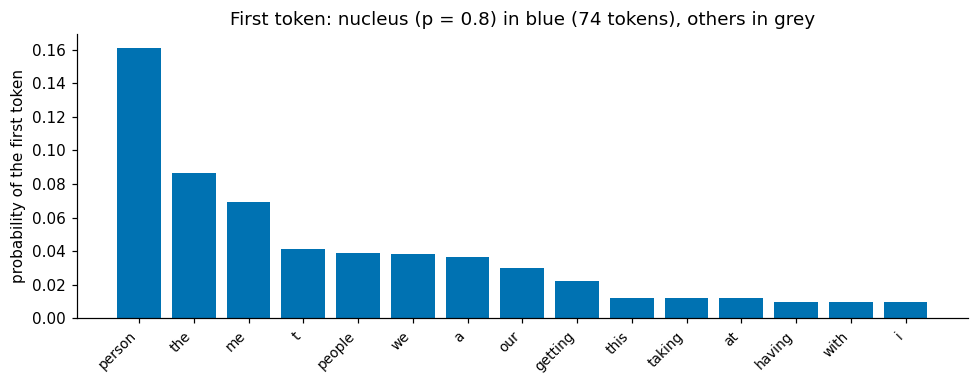

In [12]:
#@title Figure 3: the distribution of the first token and the nucleus { display-mode: "form" }
def plot_first_step(prefix_embed, top_p=0.8, n_show=15):
    with torch.no_grad():
        logits = model.gpt(inputs_embeds=prefix_embed).logits[0, -1, :]
    probs = F.softmax(logits, dim=-1)
    top_probs, top_ids = probs.topk(n_show)
    nucleus_size = int((torch.cumsum(probs.sort(descending=True).values, 0) <= top_p).sum().item()) + 1
    labels = [tokenizer.decode([i]).replace(" ", "_") for i in top_ids.tolist()]
    fig, ax = plt.subplots(figsize=(9, 3.6))
    colors = [COLORS["blue"] if k < nucleus_size else COLORS["gray"] for k in range(n_show)]
    ax.bar(range(n_show), top_probs.cpu().numpy(), color=colors)
    ax.set_xticks(range(n_show)); ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=9)
    ax.set(ylabel="probability of the first token", title=f"First token: nucleus (p = {top_p}) in blue ({nucleus_size} tokens), others in grey")
    plt.tight_layout(); plt.show()
plot_first_step(pf)

**Figure 3.** The probabilities that the model assigns to the first token of the caption ("_" marks the space that begins a word). Greedy decoding always picks the tallest bar. Top-$p$ sampling draws from the **blue** tokens (the nucleus) in proportion to their probabilities, which is why a caption can start differently each time; the grey tokens are never drawn. The more peaked the distribution, the smaller the nucleus.

## 7. Captioning a gallery of images, with a CLIP score

### 7.1 A caption quality score without reference captions
How do we judge a caption? Standard metrics compare it with human reference captions, which we do not have. But we have CLIP, which was trained to measure how well a text matches an image. The **CLIP similarity** between the image and the caption, the cosine similarity of their CLIP embeddings, is a reference-free score (this is the idea of *CLIPScore*, Hessel et al., 2021). It is cheap and correlates reasonably with human judgements, but it has the biases of CLIP itself, so it should be taken as a rough guide, not as the truth.

In [13]:
@torch.no_grad()
def clip_similarity(pil_image, captions):
    """Cosine similarity between the CLIP embedding of the image and those of the captions."""
    image_embed = F.normalize(clip_image_embedding(pil_image), dim=-1)                      # (1, 512)
    text = clip_processor.tokenizer(list(captions), padding=True, truncation=True, max_length=77, return_tensors="pt").to(device)
    pooled = clip_model.text_model(input_ids=text["input_ids"], attention_mask=text["attention_mask"]).pooler_output
    text_embed = F.normalize(clip_model.text_projection(pooled).float(), dim=-1)            # (n, 512)
    return (text_embed @ image_embed.T).squeeze(-1).cpu().numpy()

caption_rows = []
for name, im in images.items():
    pf = make_prefix(im)
    greedy = generate_greedy(model, pf)
    beam = generate_beam(model, pf, beam_size=BEAM_SIZE)[0]
    s_greedy, s_beam = clip_similarity(im, [greedy, beam])
    caption_rows.append(dict(image=name, greedy=greedy, beam=beam, sim_greedy=float(s_greedy), sim_beam=float(s_beam)))
    print(f"{name}: {beam}")

COCO 562207: person and i with an elephant.
COCO 579664: bananas on a market stall.
COCO 060623: this was the first time i 've ever had a birthday party.
COCO 165547: example of a mountain style dining room design with white walls.
COCO 334321: the dog nanny , dog sitter.
COCO 483108: passengers waiting for a train.
COCO 386164: wooden spoons on a wooden table -- stock photo #.
COCO 354533: motorcycle parked in the desert.


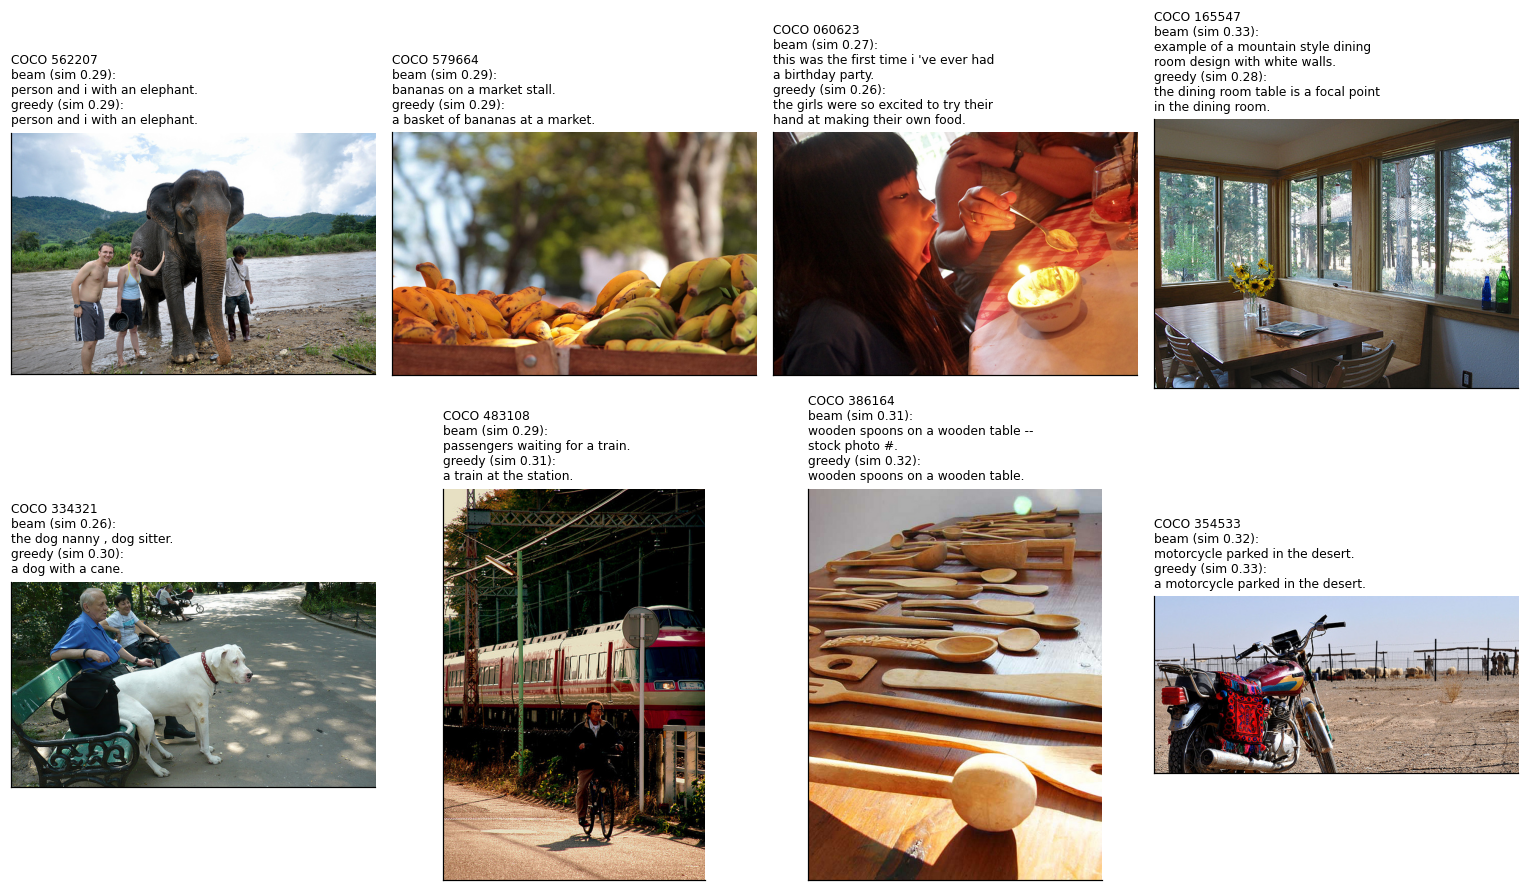

In [14]:
#@title Figure 4: captions of the gallery { display-mode: "form" }
fig, axes = plt.subplots(2, 4, figsize=(14, 8.2))
for a, row in zip(axes.ravel(), caption_rows):
    a.imshow(images[row["image"]]); a.set_xticks([]); a.set_yticks([])
    a.set_title(f"{row['image']}\nbeam (sim {row['sim_beam']:.2f}):\n" + textwrap.fill(row["beam"], 38) +
                f"\ngreedy (sim {row['sim_greedy']:.2f}):\n" + textwrap.fill(row["greedy"], 38), fontsize=8, loc="left")
for a in axes.ravel()[len(caption_rows):]:
    a.axis("off")
plt.tight_layout(); plt.show()

**Figure 4.** Each image with the caption of the beam search and of greedy decoding, and their CLIP similarity ("sim") to the image. Compare the two decoders: they often agree, and when they do not, the score tells you which sentence CLIP finds closer to the image. Judge the captions yourself, too: are all objects mentioned? Is anything invented? (The model sometimes states things that are not in the image; this is called *hallucination*.)

## 8. Looking inside

### 8.1 Does the image really matter?
If the caption is produced by GPT-2 continuing a prefix, we can test how much the prefix controls the result by **replacing the prefix** and watching the caption. We use, for the first image: (a) its own prefix, (b) the prefix of a *different* image, (c) a prefix made from an all-zero CLIP embedding, (d) a prefix from a random vector with the typical length of a CLIP embedding.

In [15]:
names = list(images)
a_name, b_name = names[0], names[1]
embed_a = clip_image_embedding(images[a_name])
embed_b = clip_image_embedding(images[b_name])
gen = torch.Generator(device=device).manual_seed(SEED)
random_embed = torch.randn(1, CLIP_SIZE, device=device, generator=gen)
random_embed = random_embed / random_embed.norm() * embed_a.norm()                 # same length as a real embedding

experiments = [(f"(a) the right image ({a_name})", embed_a), (f"(b) the prefix of ANOTHER image ({b_name})", embed_b),
               ("(c) all-zero CLIP embedding", torch.zeros_like(embed_a)), ("(d) random CLIP-like vector", random_embed)]
for label, e in experiments:
    pf_e = model.prefix_from_clip(e)
    print(f"{label:48s}: {generate_beam(model, pf_e, beam_size=BEAM_SIZE)[0]}")

(a) the right image (COCO 562207)               : person and i with an elephant.
(b) the prefix of ANOTHER image (COCO 579664)   : bananas on a market stall.
(c) all-zero CLIP embedding                     : nearing the end of the game.
(d) random CLIP-like vector                     : this is the image for the news article titled.


**Reading the result.** If the caption follows the prefix, then (a) describes the first image and (b) describes the *second* one, while the uninformative prefixes (c) and (d) should lead to a generic, image-independent sentence. This confirms that the image influences the text *only* through the prefix.

### 8.2 What does the prefix look like?
The prefix vectors live in the same 768-dimensional space as GPT-2's token embeddings, but they are not the embedding of any word. We can ask which GPT-2 **tokens** are *nearest* (in cosine similarity) to each of the 10 prefix vectors, and how large the prefix vectors are compared with real token embeddings.

In [16]:
with torch.no_grad():
    E = model.gpt.transformer.wte.weight                                                   # (50257, 768): the token embeddings
    prefix0 = make_prefix(images[a_name])[0]                                               # (10, 768)
    sims = F.normalize(prefix0, dim=-1) @ F.normalize(E, dim=-1).T                         # cosine similarity with every token
    top = sims.topk(5, dim=-1)
print(f"average length of a token embedding: {E.norm(dim=-1).mean().item():.2f} | lengths of the 10 prefix vectors: {np.round(prefix0.norm(dim=-1).cpu().numpy(), 1)}")
print("\nposition | highest cosine | the 5 nearest tokens")
for k in range(prefix0.shape[0]):
    toks = [tokenizer.decode([i]).strip() or "<space>" for i in top.indices[k].tolist()]
    print(f"{k:8d} | {top.values[k, 0].item():14.3f} | {toks}")

average length of a token embedding: 3.97 | lengths of the 10 prefix vectors: [20.5 17.5 16.1 13.4 13.7 14.7 13.4 13.4 13.8 14.1]

position | highest cosine | the 5 nearest tokens
       0 |          0.096 | ['girlfriend', 'playing', 'for', 'and', 'inside']
       1 |          0.181 | ['valley', 'village', 'jungle', 'mountain', 'countryside']
       2 |          0.178 | ['Elves', 'achel', 'couples', 'siblings', 'friendship']
       3 |          0.218 | ['crocod', 'mud', 'cooling', 'bamboo', 'elephants']
       4 |          0.315 | ['elephant', 'elephants', 'tiger', 'apes', 'ape']
       5 |          0.198 | ['smiling', 'pose', 'posing', 'smiles', 'greet']
       6 |          0.233 | ['festivals', 'rivers', 'fishermen', 'Festival', 'river']
       7 |          0.232 | ['...', 'my', '*', 'I', ']']
       8 |          0.151 | ['time', 'Canucks', '17', 'shooter', 'me']
       9 |          0.172 | ['-', '#', 'gr', '*', 'and']


**Reading the result.** The nearest tokens are not necessarily related to the image. The prefix is a vector in a *continuous* space: it does not have to correspond to words, and GPT-2 reads it through its attention layers. Compare the lengths of the prefix vectors with the length of a typical token embedding, and the highest cosine similarities with 1 (which would mean "this vector *is* that word's embedding").

## 9. Exploring the decoders and the two models

### 9.1 How does sampling change the captions?
Sampling gives different captions for different random seeds, and the temperature controls how adventurous they are. For one image we draw five captions at a low and at a high temperature, with the same nucleus $p=0.9$.

In [17]:
pf = make_prefix(images[a_name])
print(f"image {a_name}; beam search: {generate_beam(model, pf, beam_size=BEAM_SIZE)[0]}\n")
for T in (0.5, 1.0, 1.5):
    print(f"temperature {T}:")
    samples = [generate_top_p(model, pf, top_p=0.9, temperature=T, seed=SEED + k) for k in range(5)]
    sims = clip_similarity(images[a_name], samples)
    for s, sim in zip(samples, sims):
        print(f"   (sim {sim:.2f})  {s}")
    print(f"   -> {len(set(samples))} different captions out of 5; mean similarity {sims.mean():.3f}")

image COCO 562207; beam search: person and i with an elephant.

temperature 0.5:
   (sim 0.29)  person and i with an elephant.
   (sim 0.28)  the elephants are a good size for our size.
   (sim 0.30)  me and person with an elephant.
   (sim 0.30)  person with the elephants at the river bank.
   (sim 0.29)  person and i with an elephant.
   -> 4 different captions out of 5; mean similarity 0.294
temperature 1.0:
   (sim 0.30)  how to visit elephant backcountry.
   (sim 0.26)  the crowd of elephants.
   (sim 0.32)  me standing next to a huge elephant , river.
   (sim 0.26)  our group enjoyed taking the elephants.
   (sim 0.23)  all smiles at the waterfall.
   -> 5 different captions out of 5; mean similarity 0.276
temperature 1.5:
   (sim 0.28)  how miners scale elephants back at mountain lasty cook building expedition tattoo cope continent from television show together making feet cure costs beauty.
   (sim 0.16)  the crowd which looked like tiger session.
   (sim 0.24)  woman pants wel

With a low temperature the captions become similar to the greedy and beam captions (the nucleus shrinks to a few tokens); with a high temperature they become more varied and, usually, less accurate. Sampling is useful when you want *several different* captions or creative text; for the "most probable description", beam search is the better choice.

### 9.2 COCO or Conceptual Captions?
The two pre-trained models use the same architecture but were trained on different data, so they describe images in different *styles*. (If you did not select `COMPARE_MODELS` in Section 3.2, the cell below only reminds you of the option.)

In [18]:
if not COMPARE_MODELS:
    print("Set COMPARE_MODELS = True in the settings cell and re-run from there to download and compare the second model.")
else:
    other = "COCO" if MODEL == "Conceptual captions" else "Conceptual captions"
    captioners[other] = load_captioner(other)
    print(f"{'image':12s} | {MODEL}  <>  {other}")
    for name, im in list(images.items())[:6]:
        c_embed = clip_image_embedding(im)
        row = [generate_beam(captioners[m], captioners[m].prefix_from_clip(c_embed), beam_size=BEAM_SIZE)[0] for m in (MODEL, other)]
        print(f"{name:12s} | {row[0]}\n{'':12s} | {row[1]}\n")

Set COMPARE_MODELS = True in the settings cell and re-run from there to download and compare the second model.


**Reading the result.** The COCO model, trained on captions written by people who were asked to describe what they see, typically produces plain descriptions of the scene ("a man riding a wave on top of a surfboard"). The Conceptual Captions model, trained on web alt-text, tends to produce shorter, more generic and more "stock-photo" sentences, and its training texts had names and specific entities replaced by generic words. Look at your own results and form your own opinion.

## 10. Your own images, limitations and ethics

### 10.1 Try your own images
Upload an image and caption it. (In Colab, run the cell and select a file; elsewhere, set `my_image_path`.)

Saving mypic.webp to mypic.webp


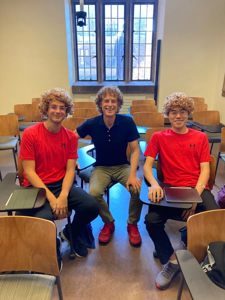

beam search : person , left , and person , right , were all smiles as they sat in the auditorium.   (CLIP similarity 0.26)
greedy      : person , left , and person , right , are excited to be back in the classroom.
top-p       : ['person is already planning on getting a similar portrait to play during his performance.', 'the crowd went wild as author handed out coffee to her team.', 'standing out from the crowd.']


In [19]:
#@title Caption your own image { display-mode: "form" }
my_image_path = "" #@param {type:"string"}
if not my_image_path and IN_COLAB:
    from google.colab import files
    uploaded = files.upload()
    if uploaded:
        my_image_path = next(iter(uploaded))
if my_image_path:
    my_image = PIL.Image.open(my_image_path).convert("RGB")
    pf_my = make_prefix(my_image)
    beam_texts, beam_sc = generate_beam(model, pf_my, beam_size=BEAM_SIZE, return_scores=True)
    display(my_image.resize((int(300 * my_image.width / my_image.height), 300)))
    print("beam search :", beam_texts[0], f"  (CLIP similarity {clip_similarity(my_image, [beam_texts[0]])[0]:.2f})")
    print("greedy      :", generate_greedy(model, pf_my))
    print("top-p       :", [generate_top_p(model, pf_my, top_p=0.9, temperature=1.0, seed=SEED + k) for k in range(3)])
else:
    print("No image selected.")

### 10.2 Limitations and ethical considerations
Captioning models are impressive, but they must be used with care:
* **Hallucination.** The model can describe objects that are not in the image, because GPT-2 completes sentences according to what is *likely*, not only what is *seen*.
* **Dataset bias.** The models reflect the data they were trained on: what people photograph and how they describe it. Captions can contain **stereotypes** about gender, age, ethnicity or occupation, and may misdescribe people or scenes that are under-represented in the data.
* **Coverage.** The training data are dominated by everyday scenes in some parts of the world. Scientific images, such as micrographs, spectra, molecular structures or plots, are far outside the training distribution, and captions for them should not be trusted.
* **A fluent sentence is not evidence of understanding.** The CLIP similarity is a useful but imperfect guide (CLIP has its own biases).

For applications that matter (accessibility, search, medical or scientific imaging), a captioning model should be validated on data from the real setting, and its output reviewed by a person.

## 11. Check your understanding

1. What are the shapes of the CLIP embedding, of the prefix, and of the input that GPT-2 receives for a caption with $L$ tokens?
2. Which parts of ClipCap are trained, and which are pre-trained and frozen (in the original idea)?
3. Why does the original `generate2` ignore `top_p` and `temperature`?
4. Why is beam search more expensive than greedy decoding, and why can it find better captions?
5. In Section 8.1, what do you expect when the prefix of another image is used, and what does that tell you about the model?

<details><summary>Answers</summary>

1. CLIP embedding: $1\times512$; prefix: $1\times10\times768$; GPT-2 input: $1\times(10+L)\times768$ (the prefix followed by the $L$ token embeddings).
2. The mapping network is trained from scratch; GPT-2 is pre-trained and (in the models used here) fine-tuned together with the mapping network; the CLIP image encoder is pre-trained and frozen.
3. After filtering the logits outside the nucleus, it picks the token with `argmax`. The most probable token is always in the nucleus and is not changed by a temperature, so the result is always the most probable token: greedy decoding.
4. It evaluates $B$ partial sentences at every step (about $B$ times the cost). It can find captions with a higher total probability because it does not commit to the single best token at each step: a sentence that begins with a slightly less probable word can be more probable as a whole.
5. The caption describes the *other* image (or a mixture): the image influences the text only through the prefix.
</details>

### Exercises
1. **Beam size.** Change `BEAM_SIZE` to 1, 3, 5 and 10. How do the captions, their scores and the running time change? What does `BEAM_SIZE = 1` correspond to?
2. **Prefix experiments.** Interpolate between the CLIP embeddings of two images, $c(\lambda)=(1-\lambda)c_A+\lambda c_B$ for $\lambda$ from 0 to 1, and caption each point. Where does the caption change from the first image to the second?
3. **Normalised embeddings.** The models were trained with *unnormalised* CLIP embeddings. Normalise the embedding to length 1 (or scale it by 2) before the mapping network. What happens to the captions?
4. **Faster generation.** Our decoders recompute the whole sequence at every step. Use the key-value cache of `transformers` (`use_cache=True`, `past_key_values`) to speed it up, and check that the captions do not change.
5. **A better score.** Compute the CLIP similarity of the 5 beams of Section 6 and re-rank them. Does the best-scoring beam by CLIP agree with the beam search score?
6. **Bias probe.** Caption images of people in different occupations or settings. Do you see systematic differences or stereotypes in the descriptions? How would you measure this systematically?

### Troubleshooting

| Symptom | What to do |
|---|---|
| The download of the weights fails or the file is tiny | Google Drive limits popular files. Download the file by hand from the link printed by the cell, and select it in the upload dialog, or re-run the cell later. |
| `RuntimeError: The weights do not match the model` | The version of `transformers` renamed some GPT-2 parameters. Note the version printed in Section 3.3 and try another version (for example `%pip install -q "transformers<5"`), then restart the session. |
| `HTTP Error` when fetching the COCO images | The COCO server may be slow or unavailable. Re-run the cell, or upload your own images (Section 10.1). |
| Captions take a long time | You are on a CPU runtime: use **Runtime → Change runtime type → GPU**. Beam search costs about `BEAM_SIZE` times the greedy decoder. |
| `CUDA out of memory` | Restart the runtime and do not load both models (`COMPARE_MODELS = False`). |
| The captions look repetitive or wrong | These models are small and trained on specific data: see Section 10.2. Try beam search, another image or the other model. |

### References
* R. Mokady, A. Hertz, A. H. Bermano, *ClipCap: CLIP prefix for image captioning* (2021). arXiv:2111.09734; code: https://github.com/rmokady/CLIP_prefix_caption
* A. Radford et al., *Learning transferable visual models from natural language supervision* (CLIP), ICML (2021). arXiv:2103.00020
* A. Radford et al., *Language models are unsupervised multitask learners* (GPT-2), OpenAI technical report (2019).
* X. L. Li, P. Liang, *Prefix-tuning: optimizing continuous prompts for generation*, ACL (2021). arXiv:2101.00190
* A. Holtzman, J. Buys, L. Du, M. Forbes, Y. Choi, *The curious case of neural text degeneration* (nucleus sampling), ICLR (2020). arXiv:1904.09751
* J. Hessel, A. Holtzman, M. Forbes, R. Le Bras, Y. Choi, *CLIPScore: a reference-free evaluation metric for image captioning*, EMNLP (2021). arXiv:2104.08718
* T.-Y. Lin et al., *Microsoft COCO: common objects in context*, ECCV (2014). arXiv:1405.0312
* P. Sharma, N. Ding, S. Goodman, R. Soricut, *Conceptual Captions: a cleaned, hypernymed, image alt-text dataset for automatic image captioning*, ACL (2018).
* A. Karpathy, L. Fei-Fei, *Deep visual-semantic alignments for generating image descriptions*, CVPR (2015). (The "Karpathy split" of COCO.)
* T. Wolf et al., *Transformers: state-of-the-art natural language processing*, EMNLP System Demonstrations (2020).